Dataset shape: (1797, 64)
Number of classes: 10


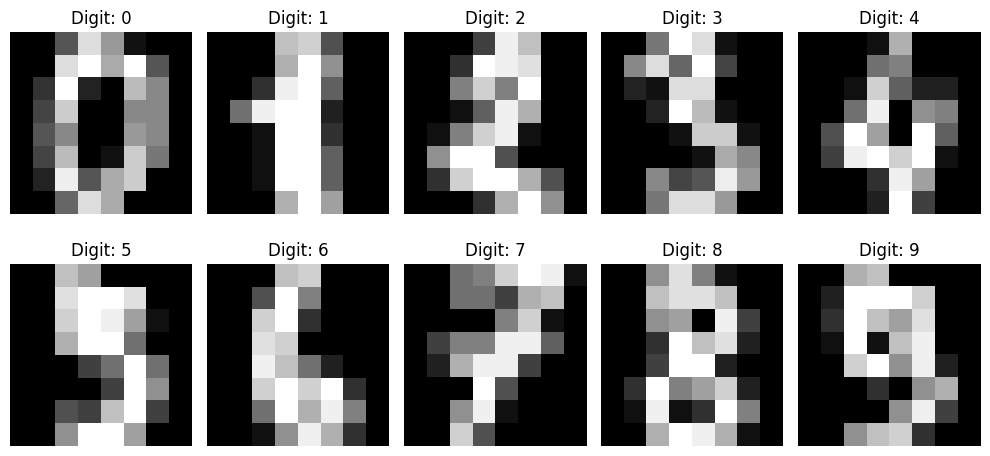

Minimum value after scaling: 0.0
Maximum value after scaling: 1.0
Training samples: 1437
Testing samples: 360

Training RBM Layer 1...
[BernoulliRBM] Iteration 1, pseudo-likelihood = -25.49, time = 0.02s
[BernoulliRBM] Iteration 2, pseudo-likelihood = -25.60, time = 0.04s
[BernoulliRBM] Iteration 3, pseudo-likelihood = -25.33, time = 0.04s
[BernoulliRBM] Iteration 4, pseudo-likelihood = -25.52, time = 0.04s
[BernoulliRBM] Iteration 5, pseudo-likelihood = -25.38, time = 0.04s
[BernoulliRBM] Iteration 6, pseudo-likelihood = -25.20, time = 0.04s
[BernoulliRBM] Iteration 7, pseudo-likelihood = -25.55, time = 0.04s
[BernoulliRBM] Iteration 8, pseudo-likelihood = -25.39, time = 0.04s
[BernoulliRBM] Iteration 9, pseudo-likelihood = -25.26, time = 0.04s
[BernoulliRBM] Iteration 10, pseudo-likelihood = -25.24, time = 0.04s
[BernoulliRBM] Iteration 11, pseudo-likelihood = -25.25, time = 0.04s
[BernoulliRBM] Iteration 12, pseudo-likelihood = -24.96, time = 0.08s
[BernoulliRBM] Iteration 13, pseud

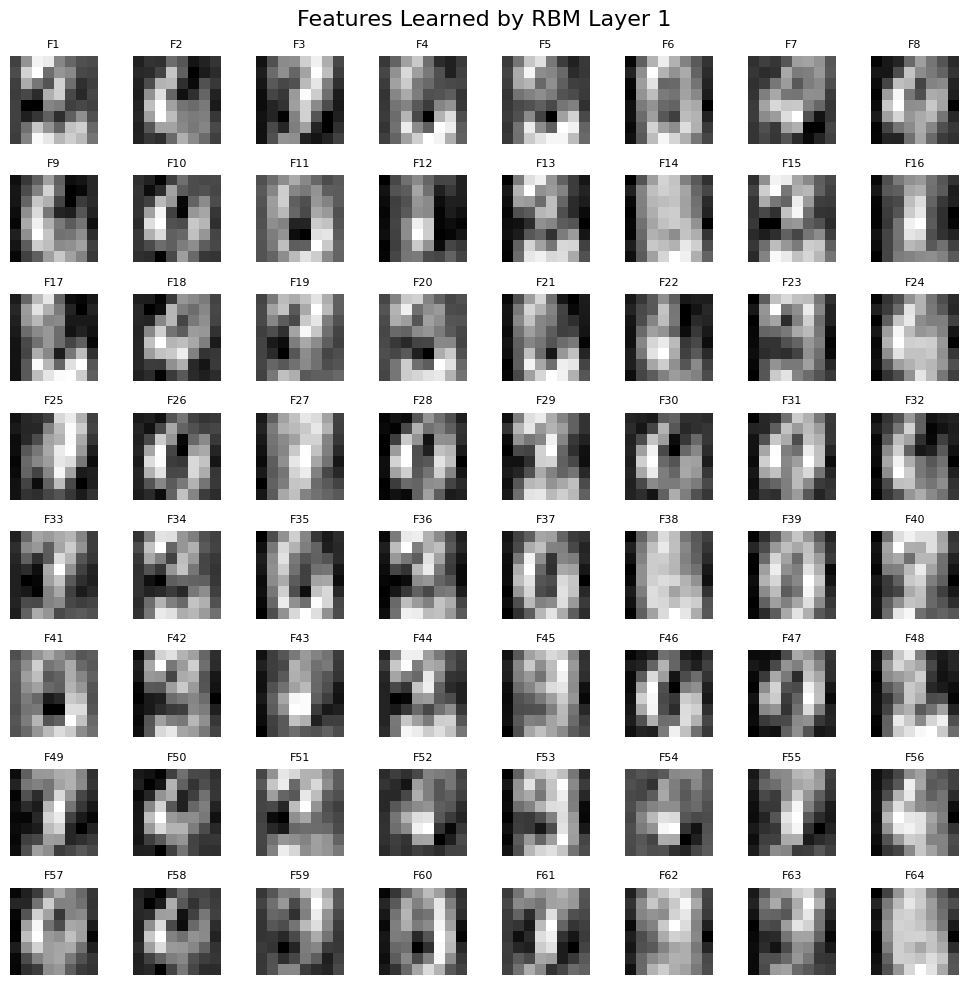

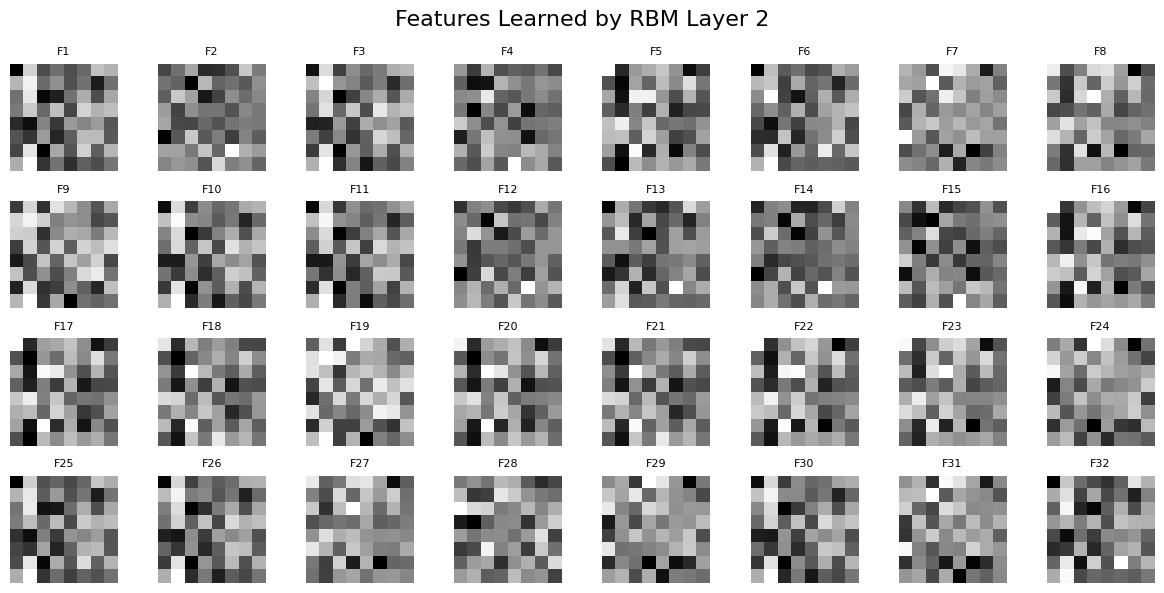

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import BernoulliRBM
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report


digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))


fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, image, label in zip(axes.ravel(),
                            digits.images[:10],
                            digits.target[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()




scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

print("Minimum value after scaling:", X_scaled.min())
print("Maximum value after scaling:", X_scaled.max())


X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])




rbm1 = BernoulliRBM(
    n_components=64,
    learning_rate=0.05,
    batch_size=32,
    n_iter=20,
    random_state=42,
    verbose=True
)



print("\nTraining RBM Layer 1...")

rbm1.fit(X_train)

print("RBM Layer 1 training completed.")




X_train_rbm1 = rbm1.transform(X_train)
X_test_rbm1 = rbm1.transform(X_test)

print("\nFeatures after RBM Layer 1:")
print("Training:", X_train_rbm1.shape)
print("Testing :", X_test_rbm1.shape)



rbm2 = BernoulliRBM(
    n_components=32,
    learning_rate=0.05,
    batch_size=32,
    n_iter=20,
    random_state=42,
    verbose=True
)



print("\nTraining RBM Layer 2...")

rbm2.fit(X_train_rbm1)

print("RBM Layer 2 training completed.")



X_train_dbn = rbm2.transform(X_train_rbm1)
X_test_dbn = rbm2.transform(X_test_rbm1)

print("\nFinal DBN feature dimensions:")
print("Training:", X_train_dbn.shape)
print("Testing :", X_test_dbn.shape)




classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classifier.fit(X_train_dbn, y_train)



y_pred = classifier.predict(X_test_dbn)




accuracy = accuracy_score(y_test, y_pred)

print("\n==========================================")
print("DBN + Logistic Regression Results")
print("==========================================")

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))




raw_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

raw_classifier.fit(X_train, y_train)

raw_pred = raw_classifier.predict(X_test)

raw_accuracy = accuracy_score(y_test, raw_pred)

print("\n==========================================")
print("Performance Comparison")
print("==========================================")

print("Logistic Regression on Raw Data:",
      raw_accuracy)

print("DBN Features + Logistic Regression:",
      accuracy)




components = rbm1.components_

fig, axes = plt.subplots(8, 8, figsize=(10, 10))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        components[i].reshape(8, 8),
        cmap="gray"
    )
    ax.axis("off")
    ax.set_title(f"F{i+1}", fontsize=8)

plt.suptitle(
    "Features Learned by RBM Layer 1",
    fontsize=16
)

plt.tight_layout()
plt.show()



components2 = rbm2.components_

plt.figure(figsize=(12, 6))

for i in range(min(32, components2.shape[0])):
    plt.subplot(4, 8, i + 1)
    plt.imshow(components2[i].reshape(8, 8),
               cmap="gray")
    plt.axis("off")
    plt.title(f"F{i+1}", fontsize=8)

plt.suptitle(
    "Features Learned by RBM Layer 2",
    fontsize=16
)

plt.tight_layout()
plt.show()